# Model 04 — Purchase Propensity
## Notebook 02: Feature Engineering and Modeling

**Target:** `Revenue` (whether this browsing session resulted in a purchase).  
**Task:** Binary classification.  
**Models:** Logistic Regression baseline and Random Forest comparison.

Important modelling decisions:
- Drop exact duplicate rows before splitting to reduce train/test contamination.
- Exclude `Revenue` from input features.
- Exclude `PageValues` from the initial model because it may encode transaction-related information that is not reliably available before the prediction decision. We can test it separately later if the deployment timing supports it.
- Use a stratified holdout split and fit preprocessing only on training data.
- Evaluate precision, recall, F1, ROC-AUC and PR-AUC, not accuracy alone.


In [1]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# Try project-relative path first; fall back to the user's Windows project path.
DATA_PATH = Path("ml/model_04_purchase_propensity/data/raw/online_shoppers_intention.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path(
        r"D:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_04_purchase_propensity\data\raw\online_shoppers_intention.csv"
    )

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Update DATA_PATH to the location of online_shoppers_intention.csv."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Original shape:", df.shape)
display(df.head())


Loaded: D:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_04_purchase_propensity\data\raw\online_shoppers_intention.csv
Original shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Data quality and target

In [2]:
print("Missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nTarget distribution:")
display(pd.DataFrame({
    "count": df["Revenue"].value_counts(),
    "percent": (df["Revenue"].value_counts(normalize=True) * 100).round(2)
}))

# Remove exact duplicate rows and document the action.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} exact duplicate rows.")
print("Shape after deduplication:", df.shape)


Missing cells: 0
Exact duplicate rows: 125

Target distribution:


,count,percent
Revenue,,
False,10422,84.53
True,1908,15.47


Removed 125 exact duplicate rows.
Shape after deduplication: (12205, 18)


## 2. Define target and exclude potential leakage

In [3]:
TARGET = "Revenue"
POTENTIAL_LEAKAGE = ["PageValues"]

# Boolean target -> integer labels: False=0, True=1
y = df[TARGET].astype(int)

# Exclude target and PageValues from predictors for the first, conservative model.
X = df.drop(columns=[TARGET] + POTENTIAL_LEAKAGE)

print("Target:", TARGET)
print("Predictor columns:", X.columns.tolist())
print("Feature count:", X.shape[1])
print("\nTarget purchase rate:", round(y.mean() * 100, 2), "%")


Target: Revenue
Predictor columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Feature count: 16

Target purchase rate: 15.63 %


## 3. Stratified train/test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Test purchase rate:", round(y_test.mean() * 100, 2), "%")


Train shape: (9764, 16) Test shape: (2441, 16)
Train purchase rate: 15.63 %
Test purchase rate: 15.65 %


## 4. Preprocessing pipeline

In [5]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
Categorical features: ['Month', 'VisitorType']


## 5. Train baseline and comparison models

In [6]:
models = {
    "Dummy baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc_average_precision": average_precision_score(y_test, proba)
    })

results_df = pd.DataFrame(results).sort_values("pr_auc_average_precision", ascending=False)
display(results_df.round(4))


,model,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision
2,Random Forest,0.7997,0.3770,0.4293,0.4015,0.7827,0.3655
1,Logistic Regression,0.6333,0.2662,0.7644,0.3949,0.7500,0.3159
0,Dummy baseline,0.8435,0.0000,0.0000,0.0000,0.5000,0.1565


## 6. Inspect the strongest model

Best by PR-AUC: Random Forest

Classification report at default threshold:
              precision    recall  f1-score   support

 No purchase       0.89      0.87      0.88      2059
    Purchase       0.38      0.43      0.40       382

    accuracy                           0.80      2441
   macro avg       0.63      0.65      0.64      2441
weighted avg       0.81      0.80      0.80      2441



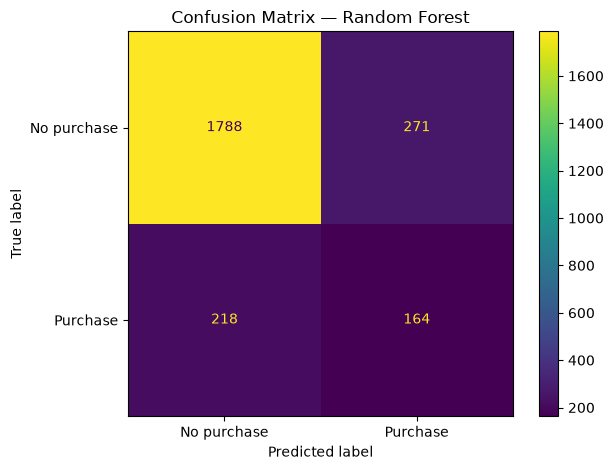

In [7]:
best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("Best by PR-AUC:", best_name)
print("\nClassification report at default threshold:")
print(classification_report(y_test, best_pred, target_names=["No purchase", "Purchase"], zero_division=0))

cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No purchase", "Purchase"]).plot()
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()


## 7. Threshold review for purchase class

In [8]:
threshold_rows = []
for threshold in [0.30, 0.40, 0.50, 0.60]:
    pred_t = (best_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0)
    })

display(pd.DataFrame(threshold_rows).round(4))


,threshold,precision,recall,f1
0,0.3,0.2715,0.8272,0.4088
1,0.4,0.3242,0.6518,0.4330
2,0.5,0.3770,0.4293,0.4015
3,0.6,0.4561,0.2723,0.3410


## 8. Save metrics and fitted pipeline

In [9]:
from pathlib import Path
import json
import joblib

# Model artifacts belong under backend/models/<model_name>/
MODEL_DIR = Path("backend/models/purchase_propensity")

# Reports belong at the Model 04 root under ml/model_04_purchase_propensity/reports/
REPORT_DIR = Path("ml/model_04_purchase_propensity/reports")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(REPORT_DIR / "model_comparison_metrics.csv", index=False)
pd.DataFrame(threshold_rows).to_csv(REPORT_DIR / "threshold_review.csv", index=False)

# Save the best preliminary pipeline selected by holdout PR-AUC.
joblib.dump(best_model, MODEL_DIR / "purchase_propensity_pipeline.joblib")

metadata = {
    "target": TARGET,
    "target_definition": "whether the current browsing session resulted in a purchase",
    "excluded_features": POTENTIAL_LEAKAGE,
    "selected_model": best_name,
    "selection_metric": "average_precision_pr_auc",
    "test_size": 0.20,
    "random_state": 42,
    "note": "Preliminary holdout result. Review PageValues leakage and threshold/business costs before production use."
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved metrics:", REPORT_DIR / "model_comparison_metrics.csv")
print("Saved threshold review:", REPORT_DIR / "threshold_review.csv")
print("Saved pipeline:", MODEL_DIR / "purchase_propensity_pipeline.joblib")
print("Saved metadata:", MODEL_DIR / "model_metadata.json")


Saved metrics: ml\model_04_purchase_propensity\reports\model_comparison_metrics.csv
Saved threshold review: ml\model_04_purchase_propensity\reports\threshold_review.csv
Saved pipeline: backend\models\purchase_propensity\purchase_propensity_pipeline.joblib
Saved metadata: backend\models\purchase_propensity\model_metadata.json


## 9. Interpretation and next steps
1. Review `model_comparison_metrics.csv`; do not select a model by accuracy alone.
2. Review the threshold table against the business trade-off between missed buyers and false positives.
3. Treat the selected holdout winner as preliminary. Use cross-validation and verify the feature availability assumptions before release.
4. `PageValues` was excluded conservatively. Only evaluate it in a separate experiment if its value is available at the actual prediction time and does not leak the target.
5. Next phase: finalize model, create inference API, then frontend probability dashboard.
